In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

## Params

In [ ]:
# V_max = 10
# V_width_array = np.arange(V_max).astype(int) + 1
V_width_array = np.array([1, 10, 20])
V_E_buffer = 0
E_width = 1

N_training_repeats = 2  
cg_params = {
    "order": 1,
}
# meta_neurons_per_time_bin = 15
N_meta_neurons = 20

critic_params = {
    "hidden_dim": 32,
    "embed_dim": 100,
    "layers": 2,
    "activation": "tanh",
}
opt_params = {"track_quantities": False, "quiet": True, "iterations": 2}
mi_measurement_params = {"quiet": True, "batch_size": 500, "N_batches": 500}

train_fraction = 0.5
samp_keep = 1

# Put variable names here for parameters we want saved.
save_vars = {
    "mi_measurement_params",
    "N_training_repeats",
    "critic_params",
    "opt_params",
    "V_width_array",
    "V_E_buffer",
    "E_width",
    "train_fraction",
    "samp_keep",
}

## Prepare data

In [113]:
data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
D = ds.DataNatScenes(data_path, mov_ind=1)
print(f'current stimulus is {D.movname}')
mov_ind = D.mov_ind
save_vars.add('mov_ind')

current stimulus is water


## Run analysis

In [114]:
experiment_dims = (len(V_width_array), N_training_repeats)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)
save_vars.update(
    {
        "mi_averages_train",
        "mi_averages_test",
        "mi_stdevs_train",
        "mi_stdevs_test",
        "train_points",
        "test_points",
    }
)

for i, V_width in tqdm(enumerate(V_width_array)):
    for training_repeat in range(N_training_repeats):
        critic_function = mds.SeparableCritic(**critic_params)
        # N_meta_neurons = V_width * meta_neurons_per_time_bin
        coarse_grainer = mds.PolynomialLayer(output_dim=N_meta_neurons, **cg_params)

        # Domains, training and test subsets
        D.reset()
        D.trim(20)
        V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep)
        current_train_points, current_test_points = tools.generate_train_test_indices(
            V.P, train_fraction
        )
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        train_points[i, training_repeat] = current_train_points
        test_points[i, training_repeat] = current_test_points

        #####
        # Train current
        als.IB(
            X=V.X,
            Y=E.X,
            coarse_grainer=coarse_grainer,
            critic_function=critic_function,
            **opt_params
        )

        # Measure InfoNCE for train
        T_train = coarse_grainer(V.X.T).numpy().T
        mi_train = als.MI_NCE(
            X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_train[i, training_repeat] = mi_train["mi"]
        mi_stdevs_train[i, training_repeat] = mi_train["mi_stdev"]
        #####

        # # Train current
        # als.train_NCE(X=V.X, Y=E.X, critic_function=critic_function, **opt_params)

        # # Measure InfoNCE for train
        # mi_train = als.MI_NCE(
        #     X=V.X, Y=E.X, critic_function=critic_function, **mi_measurement_params
        # )
        # mi_averages_train[i, training_repeat] = mi_train["mi"]
        # mi_stdevs_train[i, training_repeat] = mi_train["mi_stdev"]

        # Measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(current_test_points)
        E.subset_points(current_test_points)

        T_test = coarse_grainer(V.X.T).numpy().T
        mi_test = als.MI_NCE(
            X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_test[i, training_repeat] = mi_test["mi"]
        mi_stdevs_test[i, training_repeat] = mi_test["mi_stdev"]

        # mi_test = als.MI_NCE(
        #     X=V.X, Y=E.X, critic_function=critic_function, **mi_measurement_params
        # )
        # mi_averages_test[i, training_repeat] = mi_test["mi"]
        # mi_stdevs_test[i, training_repeat] = mi_test["mi_stdev"]

        critic_function_array[i, training_repeat] = critic_function

3it [00:18,  6.06s/it]


## Save

In [ ]:
# select variables
critic_type = type(critic_function_array[0, 0])
save_vars.update({"critic_type"})
local_dict = locals()
output_data = {k: local_dict[k] for k in save_vars}

In [36]:
# save things
timestamp = strftime("%Y.%m.%d %Hh %Mm %Ss.dat",gmtime())
# full_file_path = os.path.join(save_directory, strftime("%Y.%m.%d %Hh %Mm %Ss",gmtime())+'.dat')
full_file_path = os.path.join(save_directory, 'all opticflow K=20.dat')
print(full_file_path)

/Users/adamkline/Projects/archive/metaneurons/analyses/Markovianity/saved/all opticflow K=20.dat


In [ ]:
os.makedirs(os.path.dirname(full_file_path), exist_ok=True)
with open(full_file_path, 'wb+') as f:
            pickle.dump(output_data, f)
tools.record_parameters(full_file_path, output_data)

## Reload

In [ ]:
load_path = project_folder + '/analyses/Markovianity/saved/all opticflow K=20.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

## Skip saving and reloading

In [115]:
critic_type = type(critic_function_array[0, 0])
save_vars.update({"critic_type"})
local_dict = locals()
output_data = {k: local_dict[k] for k in save_vars}
data = Namespace(**output_data)

## Plot

In [116]:
average_test = np.average(data.mi_averages_test, axis=1)
average_train = np.average(data.mi_averages_train, axis=1)
trial_variance_test = np.diag(np.cov(data.mi_averages_test))
trial_variance_train = np.diag(np.cov(data.mi_averages_train))
full_stdevs_train = np.sqrt(np.sum(data.mi_stdevs_train**2, axis=1) + trial_variance_train)
full_stdevs_test = np.sqrt(np.sum(data.mi_stdevs_test**2, axis=1) + trial_variance_test)

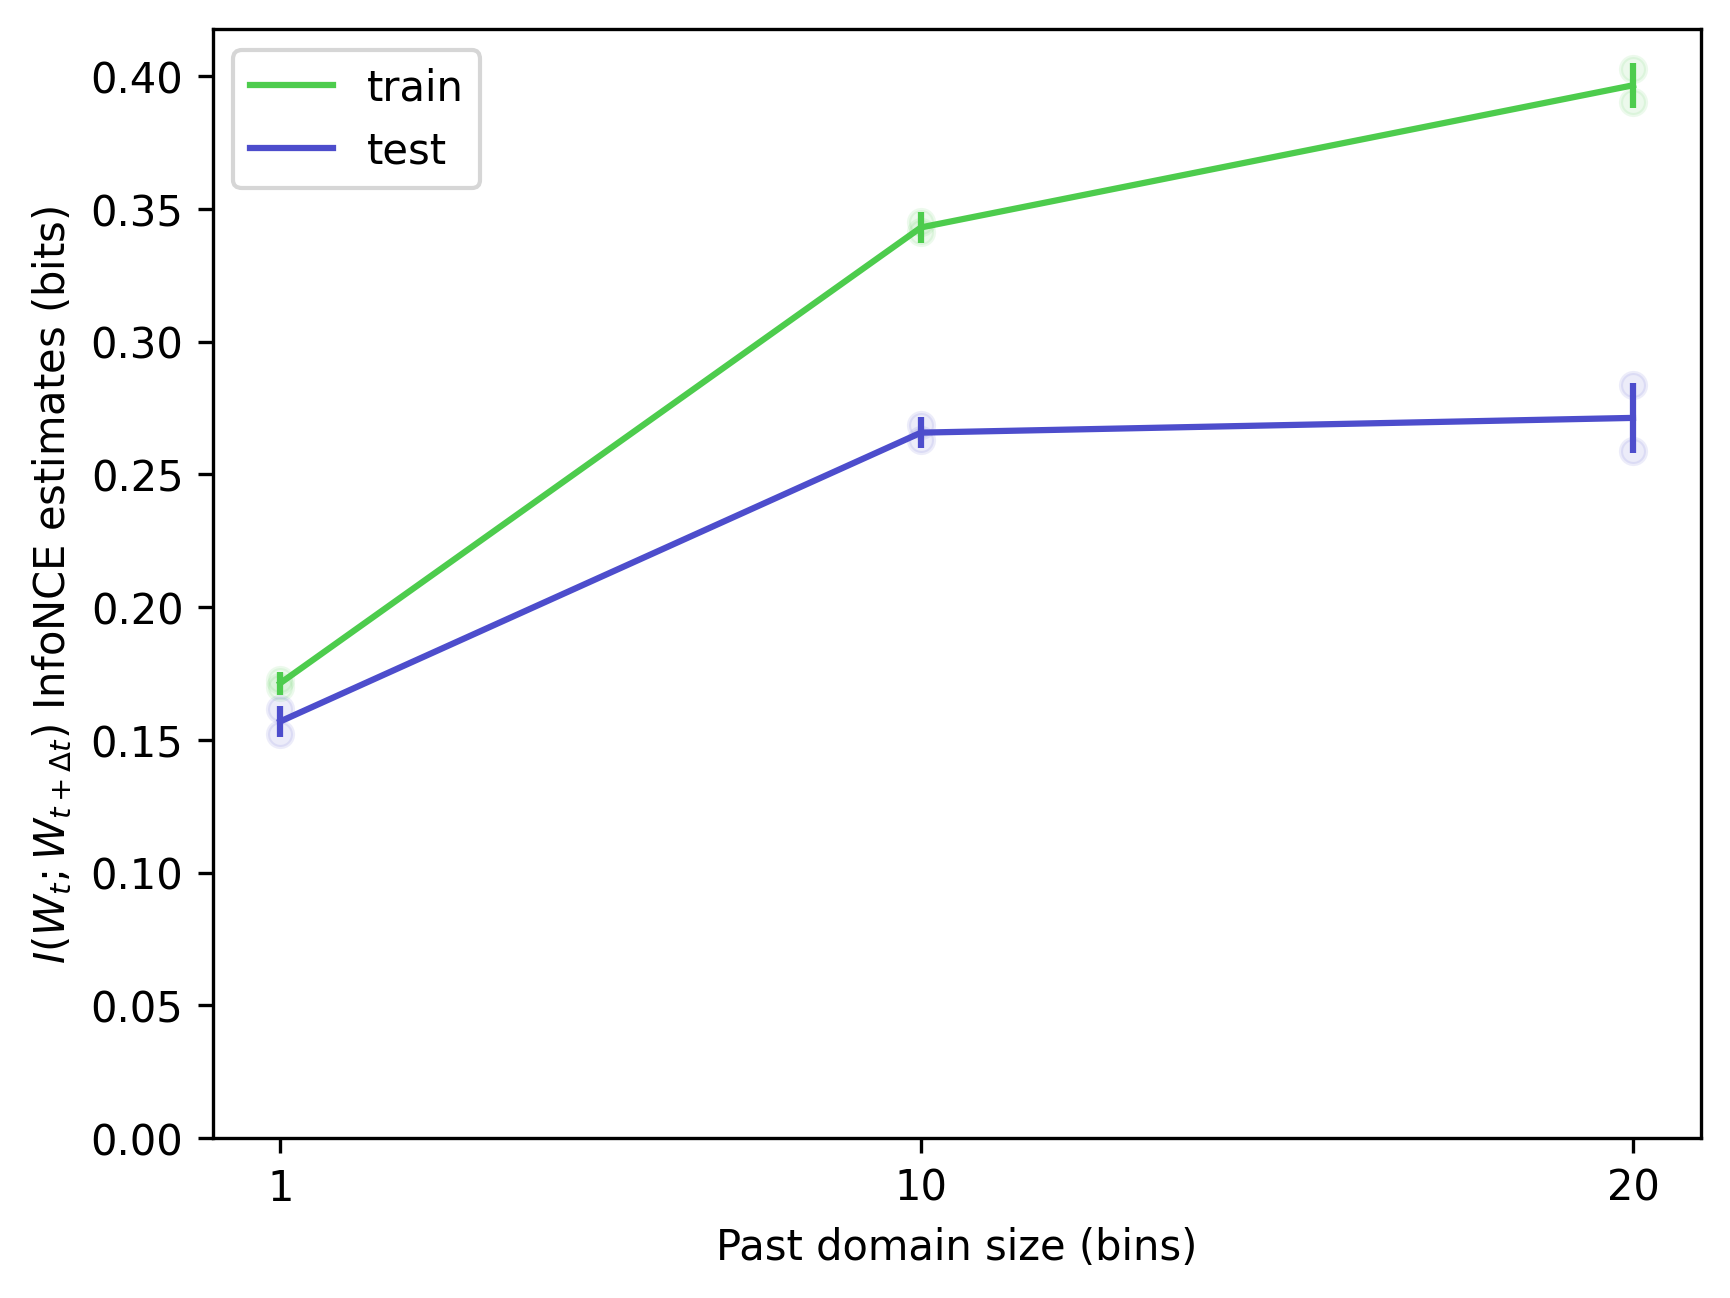

In [117]:
x = data.V_width_array

c1 = 0.3
c2 = 0.8
alp = 0.1
plt.figure(dpi=300)
plt.plot(x, average_train/np.log(2), color=(c1,c2,c1), label='train')
plt.plot(x, data.mi_averages_train/np.log(2),'o', color=(c1,c2,c1,alp))
plt.plot(x, average_test/np.log(2), color=(c1,c1,c2), label='test');
plt.plot(x, data.mi_averages_test/np.log(2),'o', color=(c1,c1,c2,alp))
plt.errorbar(x, average_train/np.log(2), yerr=full_stdevs_train, linestyle='', color=(c1,c2,c1))
plt.errorbar(x, average_test/np.log(2), yerr=full_stdevs_test, linestyle='', color=(c1,c1,c2))
plt.ylim(ymin=0)
ax = plt.gca()
ax.set_xticks(x)
# plt.title('Predictive info quickly saturates at a few meta-neurons')
plt.xlabel('Past domain size (bins)')
plt.ylabel(r'$I(W_{t};W_{t+\Delta t})$ InfoNCE estimates (bits)')
plt.legend();

In [118]:
data.mi_averages_test / np.log(2)

array([[0.16155705, 0.15240791],
       [0.2629006 , 0.26863128],
       [0.25895556, 0.28368341]])

In [119]:
np.max(data.mi_averages_test) / data.mi_averages_test[0]

array([1.75593335, 1.86134312])

In [111]:
np.max(data.mi_averages_test) / data.mi_averages_test[0]

array([1.71657126, 1.74546079])

In [18]:
x = data.V_width_array
y_train = (average_train[-1] - average_train)/np.log(2)
t_halfmax_train = tools.arg_half_max(y_train)
y_test = (average_test[-1] - average_test)/np.log(2)
t_halfmax_test = tools.arg_half_max(y_test)
tau_train = t_halfmax_train / np.log(2)
tau_test = t_halfmax_test / np.log(2)
y_train_theory = np.exp( - (x - 1) / tau_train) * y_train[0]
y_test_theory = np.exp(- (x - 1) / tau_test) * y_test[0]

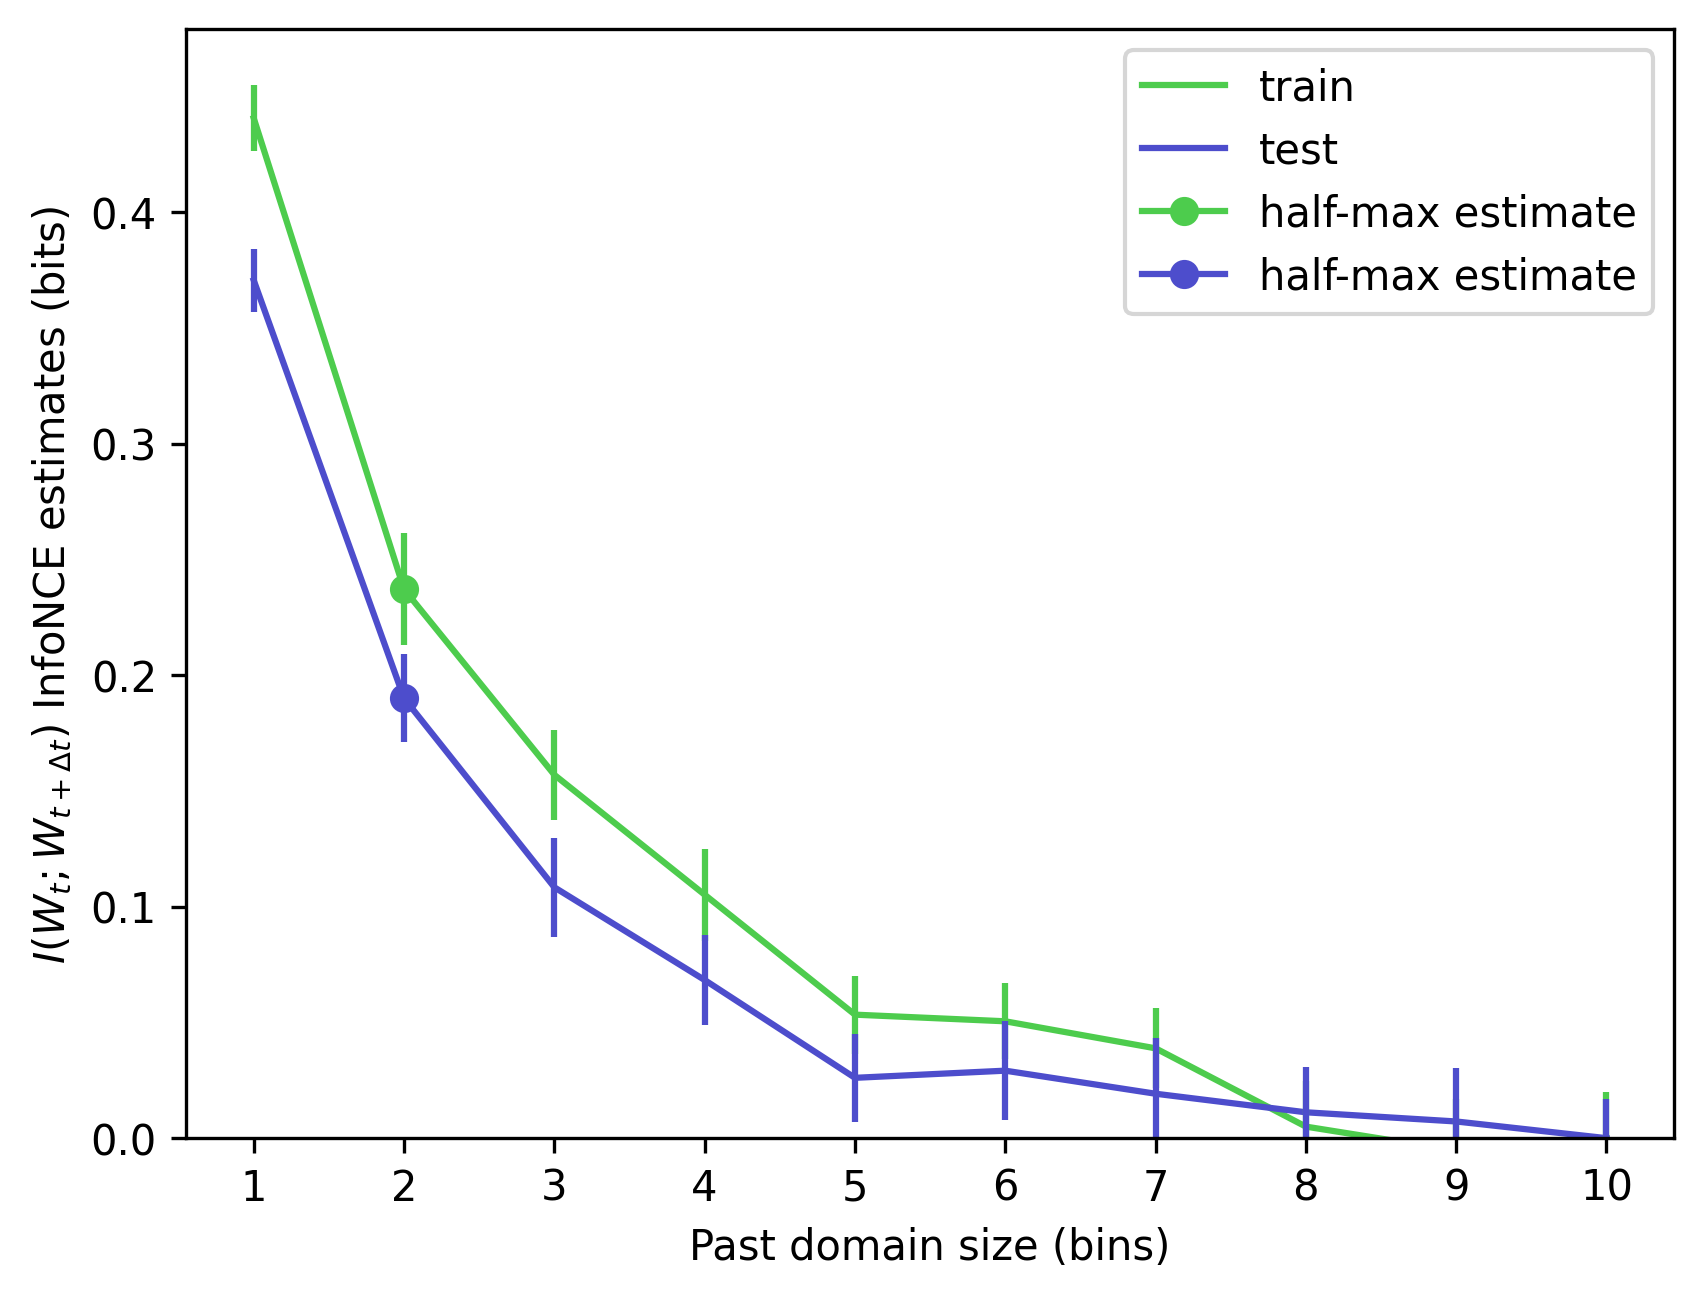

In [21]:
c1 = 0.3
c2 = 0.8
alp = 0.1
plt.figure(dpi=300)
plt.plot(x, y_train, color=(c1,c2,c1), label='train')
plt.plot(x, y_test, color=(c1,c1,c2), label='test');

# plt.plot(x, y_train_theory, 'k')
# plt.plot(x, y_test_theory, 'k')

plt.plot(x[t_halfmax_train], y_train[t_halfmax_train], color=(c1,c2,c1), marker='o', label='half-max estimate')
plt.plot(x[t_halfmax_test], y_test[t_halfmax_test], color=(c1,c1,c2), marker='o', label='half-max estimate');

plt.errorbar(x, y_train, yerr=full_stdevs_train, linestyle='', color=(c1,c2,c1))
plt.errorbar(x, y_test, yerr=full_stdevs_test, linestyle='', color=(c1,c1,c2))

plt.ylim(ymin=0)
ax = plt.gca()
ax.set_xticks(x)
# plt.title('Predictive info quickly saturates at a few meta-neurons')
plt.xlabel('Past domain size (bins)')
plt.ylabel(r'$I(W_{t};W_{t+\Delta t})$ InfoNCE estimates (bits)')
plt.legend();